<a href="https://colab.research.google.com/github/sergiocalazans/big-data-pyspark/blob/main/PJBL2_Spark_Big_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto Spark - Big Data

## Grupo: PJBL 2 16

Participantes:
- Glaucia Bispo Santos de Araujo
- Nicolly Stefany Pedroso Cordeiro
- Sérgio Henrique da Cunha Calazans

## Descrição

Você foi contratado para integrar a equipe de análise de dados de uma grande empresa
multinacional. Nessa equipe, é utilizada a tecnologia Spark para processar grandes bases de dados
utilizando a linguagem de programação Python. No projeto atual, você deverá utilizar o framework Spark
para extrair uma série de informações sobre transações comerciais internacionais realizadas pela empresa
nos últimos 30 anos. Essas transações estão armazenadas em um dataset estruturado com 10 colunas,
conforme a descrição apresentada na tabela abaixo:

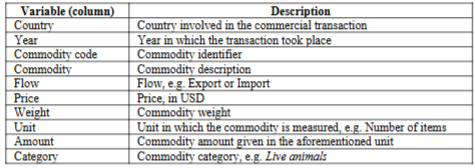

O dataset contêm mais 8 milhões de exemplos (ou seja, 8 milhões de linhas que representam as
transações comerciais da empresa). Esse dataset é disponibilizado no formato CSV em que as colunas são
separadas por ponto e vírgula “;”. Na imagem abaixo, são apresentadas as primeiras 5 linhas do arquivo,
cada uma com um total de 10 colunas.

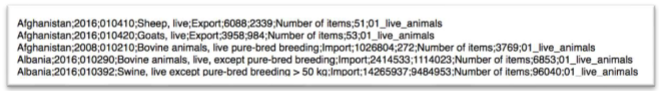

De acordo com o contexto apresentado acima, você e sua equipe são responsáveis por
desenvolver soluções em Spark capazes de responder as seguintes perguntas:

1. (0,1 ponto) Número de transações envolvendo o Brasil através de RDD. O retorno deverá ser
um único valor.

2. (0,1 ponto) Número de transações envolvendo o Brasil utilizando PairRDD. O retorno deverá
ser composto de chave (Brazil) e valor.

3. (0,1 ponto) Número de transações envolvendo o Brazil durante 2016 utilizando RDD. O
retorno deverá ser um único valor.

4. (0,1 ponto) Número de transações envolvendo o Brazil durante 2016 utilizando PairRDD. O
retorno deverá ser com chave (Brasil, 2016) e valor.

5. (0,1 ponto) Número de transações por flow e por ano ordenados por ano a partir de 2010,
transformando os valores da coluna Flow em maiúsculas. O retorno será em chave (ano,
flow) e valor.

6. (0,2 ponto) A média da coluna Price para o ano de 2016 utilizando RDD. O retorno deverá
conter apenas o valor da média.

7. (0,2 ponto) A média da coluna Price para o ano de 2016 utilizando PairRDD. O retorno deverá
conter chave (ano) e valor.

8. (0,3 ponto) O preço máximo e mínimo por categoria e por ano, ordenado por país, sendo
que a coluna categoria deve conter valores com letra maiúsculas. Utilizar PairRDD e a saída
esperada deve conter: chave (ano, categoria) e valor (máximo, mínimo).

9. (0,3 ponto) Retornar um único valor para PairRDD contendo o país com a maior exportação
(Flow=Export). A saída esperada é chave(país, flow) e valor.

10. (1,0 ponto) Transação que teve o maior preço por kg do tipo export. Buscar essa informação
e indicar em qual ano, país e categoria, ela aconteceu? Utilizar SparkSQL

Para cada um dos itens acima, forneça:
1. Será necessário retirar o cabeçalho.
2. Será necessário tratar dados faltantes.
3. Código fonte para a resolução do problema utilizando Spark em Python.
4. Questões que envolvem o uso de SparkSQL deverão conter as funções do mesmo. Não serão
aceitas retornos com consultas tradicionais de SQL.
5. O resultado da execução em um arquivo separado e no formato txt.

Para realizar o PjBL2, será necessário realizar o download do arquivo encontrado no seguinte link:

[operacoes_comerciais_inteira.csv](https://drive.google.com/file/d/1N0xJ8YnlsS8BhvtiFc_KrotglyFrelFV/view?usp=sharing)

## Implementação

### Importar Bibliotecas

In [1]:
from pyspark.sql import SparkSession
from pyspark import SparkFiles
from pyspark.sql import functions as F
from pyspark.sql.functions import col, trim

### Criar sessão e Contexto do Spark

In [2]:
# Cria a sessão Spark
spark = SparkSession.builder.appName('pjbl2').getOrCreate()

# Obtém o contexto Spark
sc = spark.sparkContext

### Carregar arquivo csv em um rdd

In [3]:
# Caminho do arquivo CSV
url = '/content/operacoes_comerciais_inteira.csv'

# Carrega os dados como RDD
rdd = sc.textFile(url)

# Exibe as primeiras 5 linhas
rdd.take(5)

['country_or_area;year;comm_code;commodity;flow;trade_usd;weight_kg;quantity_name;quantity;category',
 'Afghanistan;2016;010410;Sheep, live;Export;6088;2339;Number of items;51;01_live_animals',
 'Afghanistan;2016;010420;Goats, live;Export;3958;984;Number of items;53;01_live_animals',
 'Afghanistan;2008;010210;Bovine animals, live pure-bred breeding;Import;1026804;272;Number of items;3769;01_live_animals',
 'Albania;2016;010290;Bovine animals, live, except pure-bred breeding;Import;2414533;1114023;Number of items;6853;01_live_animals']

### Tratamento do CSV e criação do RDD

In [4]:
# Identifica o cabeçalho do CSV
header = rdd.first()

# Remove o cabeçalho
rdd = rdd.filter(lambda linha: linha != header)

# Separa as colunas e mantém registros com 10 campos
rdd = rdd.\
    map(lambda linha: linha.split(';')).\
    filter(lambda colunas: len(colunas) == 10)


In [5]:
# Exibe os primeiros registros
rdd.take(5)

[['Afghanistan',
  '2016',
  '010410',
  'Sheep, live',
  'Export',
  '6088',
  '2339',
  'Number of items',
  '51',
  '01_live_animals'],
 ['Afghanistan',
  '2016',
  '010420',
  'Goats, live',
  'Export',
  '3958',
  '984',
  'Number of items',
  '53',
  '01_live_animals'],
 ['Afghanistan',
  '2008',
  '010210',
  'Bovine animals, live pure-bred breeding',
  'Import',
  '1026804',
  '272',
  'Number of items',
  '3769',
  '01_live_animals'],
 ['Albania',
  '2016',
  '010290',
  'Bovine animals, live, except pure-bred breeding',
  'Import',
  '2414533',
  '1114023',
  'Number of items',
  '6853',
  '01_live_animals'],
 ['Albania',
  '2016',
  '010392',
  'Swine, live except pure-bred breeding > 50 kg',
  'Import',
  '14265937',
  '9484953',
  'Number of items',
  '96040',
  '01_live_animals']]

### Função para baixar o arquivo

In [6]:
# Função para baixar o arquivo das saídas em txt
def baixar_arquivo(rdd, nome_arquivo):
  rdd.coalesce(1).saveAsTextFile(nome_arquivo)

In [7]:
# Teste
rdd_teste = sc.parallelize([1, 2, 3, 4, 5])
baixar_arquivo(rdd_teste, 'saida_teste.txt')

### 1. (0,1 ponto) Número de transações envolvendo o Brasil através de RDD. O retorno deverá ser um único valor.

In [8]:
# Filtra as transações que envolvem o Brasil
brazil = rdd.\
    filter(lambda colunas: colunas[0].strip() == 'Brazil')

# Conta as transações utilizando RDD
brazil_count = brazil.\
    map(lambda colunas: 1).\
    reduce(lambda x, y: x + y)

# Exibe o resultado
brazil_count

184748

In [9]:
# Salva o resultado em TXT
baixar_arquivo(sc.parallelize([brazil_count]), 'brazil_count.txt')

2. (0,1 ponto) Número de transações envolvendo o Brasil utilizando PairRDD. O retorno deverá ser composto de chave (Brazil) e valor.

In [10]:
# Cria um PairRDD com país e quantidade inicial
pairRDD_country = rdd.\
    filter(lambda colunas: colunas[0].strip() != '').\
    map(lambda colunas: (colunas[0], 1))

# Seleciona somente as transações do Brasil
pairRDD_brazil = pairRDD_country.\
    filter(lambda x: x[0] == 'Brazil')

# Soma as transações pela chave
pairRDD_brazil_reduce = (
    pairRDD_brazil
    .reduceByKey(lambda x, y: x + y)
)

# Exibe o resultado
pairRDD_brazil_reduce.collect()

[('Brazil', 184748)]

In [11]:
# Salva o resultado em TXT
baixar_arquivo(pairRDD_brazil_reduce, 'brazil_pairRDD.txt')

3. (0,1 ponto) Número de transações envolvendo o Brazil durante 2016 utilizando RDD. O retorno deverá ser um único valor.

In [12]:
# Filtra as transações do Brasil em 2016
rdd_brazil_2016 = rdd.\
    filter(lambda colunas: colunas[0].strip() == 'Brazil' and
            colunas[1].strip() == '2016')

# Conta as transações
brazil_2016_count = rdd_brazil_2016.count()

# Exibe o resultado
brazil_2016_count

6210

In [13]:
# Salva o resultado em TXT
baixar_arquivo(sc.parallelize([brazil_2016_count]), 'brazil_2016_count.txt')

4. (0,1 ponto) Número de transações envolvendo o Brazil durante 2016 utilizando PairRDD. O retorno deverá ser com chave (Brasil, 2016) e valor.

In [14]:
# Cria um PairRDD com chave (país, ano)
pairRDD_brazil_2016 = rdd.\
    filter(lambda colunas:
            colunas[0].strip() == 'Brazil' and
            colunas[1].strip() == '2016').\
    map(lambda colunas: (
        (colunas[0], colunas[1]), 1
    ))

# Soma as transações pela chave
pairRDD_brazil_2016_reduce = pairRDD_brazil_2016.\
    reduceByKey(lambda x, y: x + y)

# Exibe o resultado
pairRDD_brazil_2016_reduce.collect()

[(('Brazil', '2016'), 6210)]

In [15]:
# Salva o resultado em TXT
baixar_arquivo(pairRDD_brazil_2016_reduce, 'brazil_pairRDD_2016_reduce.txt')

5. (0,1 ponto) Número de transações por flow e por ano ordenados por ano a partir de 2010, transformando os valores da coluna Flow em maiúsculas. O retorno será em chave (ano, flow) e valor.

In [16]:
# Cria pares com chave (ano, flow) e valor 1
pairRDD_flow_year = rdd.\
    filter(lambda colunas:
            colunas[1].strip().isdigit() and
            colunas[4].strip() != '').\
    filter(lambda colunas: int(colunas[1]) >= 2010).\
    map(lambda colunas: (
        (colunas[1], colunas[4].strip().upper()), 1
    )).\
    reduceByKey(lambda x, y: x + y).\
    sortByKey()

# Exibe os primeiros resultados
pairRDD_flow_year.take(5)

[(('2010', 'EXPORT'), 125013),
 (('2010', 'IMPORT'), 222447),
 (('2010', 'RE-EXPORT'), 17058),
 (('2010', 'RE-IMPORT'), 9273),
 (('2011', 'EXPORT'), 125909)]

In [17]:
# Salva o resultado em TXT
baixar_arquivo(pairRDD_flow_year, 'pairRDD_flow_year.txt')

6. (0,2 ponto) A média da coluna Price para o ano de 2016 utilizando RDD. O retorno deverá conter apenas o valor da média.

In [18]:
# Filtra o ano de 2016 e remove preços vazios ou inválidos
rdd_price_2016 = rdd.\
    filter(lambda colunas: colunas[1].strip() == '2016').\
    filter(lambda colunas:
            colunas[5].strip().lstrip('+-')
            .replace('.', '', 1).isdigit()).\
    map(lambda colunas: float(colunas[5]))

# Calcula a média dos preços
rdd_price_2016_avg = rdd_price_2016.mean()

# Exibe o resultado
rdd_price_2016_avg

137984606.1966805

In [19]:
# Salva a média em TXT
baixar_arquivo(sc.parallelize([rdd_price_2016_avg]), 'rdd_price_2016_avg.txt')

7. (0,2 ponto) A média da coluna Price para o ano de 2016 utilizando PairRDD. O retorno deverá conter chave (ano) e valor.

In [20]:
# Cria um PairRDD com ano e preço
pairRDD_price_2016 = rdd.\
    filter(lambda colunas: colunas[1].strip() == '2016').\
    filter(lambda colunas:
            colunas[5].strip().lstrip('+-')
            .replace('.', '', 1).isdigit()).\
    map(lambda colunas: (
        colunas[1], (float(colunas[5]), 1)
    ))

# Soma os preços e as quantidades por ano
pairRDD_price_2016_avg = pairRDD_price_2016.\
    reduceByKey(lambda x, y: (
        x[0] + y[0],
        x[1] + y[1]
    )).\
    mapValues(lambda x: x[0] / x[1])

# Exibe o resultado
pairRDD_price_2016_avg.collect()

[('2016', 137984606.1966806)]

In [21]:
# Salva o resultado em TXT
baixar_arquivo(pairRDD_price_2016_avg, 'pairRDD_price_2016_avg.txt')

8. (0,3 ponto) O preço máximo e mínimo por categoria e por ano, ordenado por país, sendo que a coluna categoria deve conter valores com letra maiúsculas. Utilizar PairRDD e a saída esperada deve conter: chave (ano, categoria) e valor (máximo, mínimo).

In [22]:
# Cria um PairRDD com ano, categoria e preços
pairRDD_year_category = rdd.\
    filter(lambda colunas:
            colunas[1].strip() != '' and
            colunas[9].strip() != '').\
    filter(lambda colunas:
            colunas[5].strip().lstrip('+-')
            .replace('.', '', 1).isdigit()).\
    map(lambda colunas: (
        (colunas[1], colunas[9].strip().upper()),
        (float(colunas[5]), float(colunas[5]))
    )).\
    reduceByKey(lambda x, y: (
        max(x[0], y[0]),
        min(x[1], y[1])
    )).\
    sortByKey()

# Exibe os primeiros resultados
pairRDD_year_category.take(5)

[(('1988', '01_LIVE_ANIMALS'), (180808372.0, 109.0)),
 (('1988', '02_MEAT_AND_EDIBLE_MEAT_OFFAL'), (1495935657.0, 23.0)),
 (('1988', '03_FISH_CRUSTACEANS_MOLLUSCS_AQUATIC_INVERTEBRATES_NE'),
  (157683193.0, 18.0)),
 (('1988', '04_DAIRY_PRODUCTS_EGGS_HONEY_EDIBLE_ANIMAL_PRODUCT_NES'),
  (1474784000.0, 12.0)),
 (('1988', '05_PRODUCTS_OF_ANIMAL_ORIGIN_NES'), (222282000.0, 7.0))]

In [23]:
# Salva o resultado em TXT
baixar_arquivo(pairRDD_year_category, 'pairRDD_year_category.txt')

9. (0,3 ponto) Retornar um único valor para PairRDD contendo o país com a maior exportação (Flow=Export). A saída esperada é chave(país, flow) e valor.

In [24]:
# Cria um PairRDD com as exportações por país
pairRDD_country_export = rdd.\
    filter(lambda colunas:
            colunas[0].strip() != '' and
            colunas[4].strip().lower() == 'export').\
    filter(lambda colunas:
            colunas[5].strip().lstrip('+-')
            .replace('.', '', 1).isdigit()).\
    map(lambda colunas: (
        (colunas[0], 'Export'),
        float(colunas[5])
    )).\
    reduceByKey(lambda x, y: x + y)


# Identifica o país com o maior valor total exportado
maior_exportacao = pairRDD_country_export.reduce(lambda x, y: x if x[1] >= y[1] else y)

# Cria um PairRDD contendo somente o maior resultado
pairRDD_max_export = sc.parallelize([maior_exportacao])

# Exibe o resultado
pairRDD_max_export.collect()

[(('EU-28', 'Export'), 37135546884367.0)]

In [25]:
# Salva o resultado em TXT
baixar_arquivo(pairRDD_max_export,'pairRDD_max_export.txt')

10. (1,0 ponto) Transação que teve o maior preço por kg do tipo export. Buscar essa informação e indicar em qual ano, país e categoria, ela aconteceu? Utilizar SparkSQL

In [26]:
# Leitura do CSV e remoção do cabeçalho
df = spark.read.csv(url, header=True, sep=";")

In [27]:
# Tratamento de dados faltantes

df = df.dropna(subset=[
    "year",
    "country_or_area",
    "category",
    "flow",
    "trade_usd",
    "weight_kg"
])

df = df.filter(
    (trim(col("year")) != "") &
    (trim(col("country_or_area")) != "") &
    (trim(col("category")) != "") &
    (trim(col("flow")) != "") &
    (trim(col("trade_usd")) != "") &
    (trim(col("weight_kg")) != "")
)

In [28]:
# Identifica a exportação com o maior preço por kg
resultado = (
    df
    # Seleciona somente transações de exportação
    .filter(F.lower(F.trim(F.col('flow'))) == 'export')

    # Converte os valores para números decimais
    .withColumn('trade_usd', F.col('trade_usd').cast('double'))
    .withColumn('weight_kg', F.col('weight_kg').cast('double'))

    # Remove pesos nulos ou iguais a zero
    .filter(
        F.col('trade_usd').isNotNull() &
        F.col('weight_kg').isNotNull() &
        (F.col('weight_kg') > 0)
    )

    # Calcula o preço por quilograma
    .withColumn(
        'price_per_kg',
        F.col('trade_usd') / F.col('weight_kg')
    )

    # Seleciona as colunas solicitadas
    .select(
        'year',
        'country_or_area',
        'category',
        'price_per_kg'
    )

    # Ordena pelo maior preço por kg
    .orderBy(F.col('price_per_kg').desc())

    # Retorna somente a maior transação
    .limit(1)
)

# Exibe o resultado
resultado.show(truncate=False)

+----+---------------+--------------------------------------------+------------+
|year|country_or_area|category                                    |price_per_kg|
+----+---------------+--------------------------------------------+------------+
|1999|Norway         |89_ships_boats_and_other_floating_structures|2.926688E8  |
+----+---------------+--------------------------------------------+------------+



In [29]:
# Converte as colunas do resultado em uma única linha de texto
resultado_txt = resultado.select(
    F.concat_ws(";", *resultado.columns).alias("value")
)

# Salva o resultado
resultado_txt.coalesce(1).write.mode("overwrite").text("questao10.txt")